# ResNet-18 Nesterov follow-up — clean-v4

This replaces the accumulating patch workflow in notebook 03. **Do not copy any old patch cells into this notebook.** The executed notebook and original results are preserved.

The original 10-epoch pilot completed: SGD **89.36%**, SAM **88.02%**, FGSM **79.52%** clean validation accuracy. This follow-up changes ordinary momentum to **Nesterov momentum for all three methods**, matching the released optimizer choice. It does not promise to improve SAM or reproduce the paper's WideResNet result.

**Run in order:** optional setup → configuration → write worker → diagnostics → benchmark → timing plots → optional pilot → accuracy plots. If your Colab environment still exists, skip section 1. Each phase is separate and reports its own status. No string-replacement patches and no append-to-script cells are used.

**What is fixed:** repeated append cells could create duplicate worker code; fragile patches expected exact source text; the reference diagnostic compared different compilation boundaries. This version writes exactly one worker, verifies its hash/config before launch, uses matching whole-step JIT for the reference, and collects all diagnostic outcomes before deciding whether benchmarking can proceed.

**Verification limit:** source generation and orchestration are checked locally; GPU execution of this revision is still pending. A failed diagnostic remains a failure and blocks training. No additional tolerance relaxation is introduced.


## Evidence-based diagnostic policy update
The supplied probe found differences even when calling the SAME compiled SAM function repeatedly on identical inputs (maximum 4.77257e-4 in model/optimizer/BN output). The production and reference JAXPR texts match after normalizing only function names and object addresses. Thus pointwise equivalence is not a reliable algorithm-correctness gate on this runtime.

Revision clean-v4 keeps the numerical comparison and all existing tolerances but labels its mismatch as a warning when traced operations AND captured constants match. Finite outputs, zero-perturbation checks and perturbation budgets remain required. Graph agreement checks consistency of the two formulations, not independent proof that the entire training method is correct. `passed_with_numerical_warning` allows exploratory benchmarking/pilot training while preserving the evidence. It does not establish that numerical variability explains the earlier accuracy gap. No training algorithm or precision was changed.

Existing failed run records are not edited. Run sections 2–4 again for a fresh folder and revised diagnostics; section 1 need not be repeated in the working runtime. Section 4B can be skipped because its evidence has already been inspected. Then run sections 5–6 and optionally the pilot. The updated GPU gate still needs execution on your runtime.


## Experiment contract
CIFAR-10, ResNet-18 with a 3x3 stride-1 CIFAR stem, no max-pool, batch 128, seed 42, fixed stratified 45k/5k training/validation split, clean held-out validation, official test set unused. Crop/flip augmentation and pixel normalization match the original pilot. All methods use the same initial weights and batch stream.

LR 0.1; momentum 0.9 with **Nesterov**; WD 0.0005 on all parameters; clipping at global norm 5; FP32; 10-epoch cosine schedule; 351 full batches per epoch. SAM rho 0.05 with L2 norm over all parameter gradients; original weights receive the outer-gradient update; retain first-pass BN state. FGSM epsilon 4/255 is applied in [0,1] pixel space, detached, clipped, and used for 100% adversarial training; retain clean-pass BN state. No robustness claims are made from clean accuracy.

The SAM implementation follows the released JAX code's regularization convention (L2 included in inner and outer gradients). Paper Eq.1 instead displays regularization outside the inner maximization. The full paper setup also differs in model, epochs, batch size, m, seeds and evaluation split: see [SAM paper](https://arxiv.org/abs/2010.01412), Algorithm 1, Section 3.1, Figure 3, Tables 1 and 6. Our short pilot is not a paper-table replication.

Diagnostic tolerances are recorded explicitly: rtol=2e-4; atol=1e-5 for weights, 5e-5 for optimizer state, 2e-6 for BN. They were chosen after inspecting the previous zero-rho discrepancy report. They are engineering checks, not statistical error bounds or proof that all GPU numerical behavior is correct.


## 1. Optional Colab setup
Skip this section only if this runtime has already passed the dependency import checks. An existing Python executable alone does not mean packages are installed. Select a GPU runtime first. On a fresh runtime the first cell installs Conda and restarts the kernel; continue with the next cell after restart. This reuses the pinned project stack.


In [1]:
from pathlib import Path
if Path('/usr/local/envs/sam/bin/python').exists():
    print('Python environment found. Run the next setup cell to install/verify its packages.')
else:
    import sys, subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'condacolab'], check=True)
    import condacolab
    condacolab.install()



📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:12
🔁 Restarting kernel...


In [2]:
from pathlib import Path
import subprocess, os, glob
repo_setup = Path('/content/work/sam')
repo_setup.parent.mkdir(parents=True, exist_ok=True)
if not repo_setup.exists():
    subprocess.run(['git','clone','-b','repro','https://github.com/Siddharth-magesh/sam-replication.git',str(repo_setup)],check=True)
py_setup = Path('/usr/local/envs/sam/bin/python')
if not py_setup.exists():
    subprocess.run(['mamba','create','-n','sam','python=3.8','-y'],check=True)
subprocess.run(['mamba','install','-n','sam','-c','conda-forge','cudatoolkit=11.0','cudnn=8.0.5','-y'],check=True)
lines=(repo_setup/'requirements.txt').read_text().splitlines()
fixed=[s.replace('absl-py==0.11.0','absl-py==0.10.0') for s in lines if not s.startswith('jaxlib')]
Path('/tmp/sam_requirements_fixed.txt').write_text('\n'.join(fixed)+'\n')
subprocess.run([str(py_setup),'-m','pip','install','jaxlib==0.1.57+cuda110','-f','https://storage.googleapis.com/jax-releases/jax_cuda_releases.html'],check=True)
subprocess.run([str(py_setup),'-m','pip','install','-r','/tmp/sam_requirements_fixed.txt'],check=True)
os.environ['LD_LIBRARY_PATH']='/usr/local/envs/sam/lib:'+os.environ.get('LD_LIBRARY_PATH','')
candidates=glob.glob('/usr/local/envs/sam/**/libdevice*.bc',recursive=True) or glob.glob('/usr/local/cuda*/nvvm/libdevice/libdevice*.bc')
assert candidates, 'CUDA libdevice is missing; inspect the environment setup.'
destination=Path('/usr/local/cuda-11.0/nvvm/libdevice/libdevice.10.bc')
destination.parent.mkdir(parents=True,exist_ok=True)
if not destination.exists(): destination.symlink_to(candidates[0])
# Verify packages using the SAME interpreter used by the experiment.
check = """
import sys
import numpy, jax, jaxlib, flax, tensorflow, tensorflow_datasets
assert sys.version_info[:2] == (3, 8), sys.version
assert numpy.__version__ == '1.18.5', numpy.__version__
assert jax.__version__ == '0.2.6', jax.__version__
assert jaxlib.__version__.split('+')[0] == '0.1.57', jaxlib.__version__
assert flax.__version__ == '0.2.2', flax.__version__
print('Environment imports passed:', sys.executable)
print('NumPy:', numpy.__version__, 'JAX:', jax.__version__, 'Flax:', flax.__version__)
"""
subprocess.run([str(py_setup),'-c',check],check=True)
print('Dependencies installed and imports verified. Continue to section 2.')


Dependencies installed and imports verified. Continue to section 2.


Use the existing TFDS cache at `/root/tensorflow_datasets`. If it is absent, the worker downloads CIFAR-10 through TFDS; download time is excluded from the benchmark and may be slow. You can copy the team cache using the original setup notebook’s cache-download cell.


## 2. Configure a new run
Run once per experiment. Rerunning this cell intentionally creates a new folder; it does not resume a pilot. Use a mounted Drive path for OUTPUT_ROOT if you want persistent storage. Keep the defaults for the one-factor Nesterov comparison.


In [4]:
import os, json, subprocess, uuid, hashlib, ast, zipfile
from pathlib import Path
import ast
from datetime import datetime
PY = Path('/usr/local/envs/sam/bin/python')
REPO = Path('/content/work/sam')
OUTPUT_ROOT = Path('/content/runs/resnet18_clean_v3')
assert PY.is_file(), 'Run section 1 or set PY to the pinned environment.'
assert (REPO/'sam_jax/imagenet_models/resnet.py').is_file(), 'Repository is missing.'
RUN = OUTPUT_ROOT / (datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True,exist_ok=False)
SCRIPT = RUN/'experiment.py'
CFG = dict(seed=42,split_seed=42,nesterov=True,batch_size=128,warmup=20,timed_steps=100,
           epochs=10,lr=0.1,momentum=0.9,weight_decay=0.0005,clip=5.0,rho=0.05,
           epsilon=4/255,budget_seconds=3600,data_dir='/root/tensorflow_datasets',
           repo=str(REPO),output=str(RUN))
(RUN/'config.json').write_text(json.dumps(CFG,indent=2))
ENV=os.environ.copy()
ENV['CUDA_VISIBLE_DEVICES']='0'
ENV['XLA_PYTHON_CLIENT_PREALLOCATE']='false'
ENV['LD_LIBRARY_PATH']=str(PY.parent.parent/'lib')+':'+ENV.get('LD_LIBRARY_PATH','')
print('Current run:',RUN)
print('Revision: clean-v4; Nesterov:',CFG['nesterov'])


Current run: /content/runs/resnet18_clean_v3/20261113_230151_a29033
Revision: clean-v4; Nesterov: True


## 3. Write the complete worker
This is the only worker-writing cell. Rerunning it writes the same file; it never appends. After a phase has started, changing its worker requires a fresh run folder. The Python source inside WORKER_SOURCE is the entire experiment, including diagnostics.


In [5]:
WORKER_SOURCE = r'''AUDIT_REVISION = 'clean-v4'
import os, sys, json, time, math, platform, subprocess, traceback, hashlib, re
from pathlib import Path
import numpy as np
import tensorflow as tf
# TensorFlow reads data only; reserve GPU memory for JAX.
tf.config.experimental.set_visible_devices([], 'GPU')
import tensorflow_datasets as tfds
import jax
import jax.numpy as jnp
import flax
from flax import nn, optim, serialization
C = json.loads(Path(sys.argv[1]).read_text())
OUT = Path(C['output'])
phase = sys.argv[2]
sys.path.insert(0, C['repo'])
from sam_jax.imagenet_models.resnet import ResNetBlock
METHODS = ['SGD', 'SAM', 'FGSM']
B = C['batch_size']

def ready(tree):
    for leaf in jax.tree_leaves(tree):
        if hasattr(leaf, 'block_until_ready'):
            leaf.block_until_ready()
    return tree

def save(name, value):
    tmp = OUT / (name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2))
    tmp.replace(OUT / name)

assert jax.__version__ == '0.2.6' and flax.__version__ == '0.2.2', 'Use the pinned project environment.'
assert len(jax.devices()) == 1 and jax.devices()[0].platform == 'gpu', 'A single visible GPU is required.'
start = time.perf_counter()
ds = tfds.load('cifar10:3.0.2', split='train', data_dir=C['data_dir'], batch_size=-1)
a = tfds.as_numpy(ds)
images, labels = a['image'], a['label'].astype(np.int32)
rng = np.random.RandomState(C['split_seed'])
train_idx, val_idx = [], []
for label in range(10):
    ids = rng.permutation(np.flatnonzero(labels == label))
    val_idx.extend(ids[:500]); train_idx.extend(ids[500:])
train_idx, val_idx = np.array(train_idx), np.array(val_idx)
assert len(train_idx) == 45000 and len(val_idx) == 5000
np.savez(OUT / 'split_indices.npz', train=train_idx, validation=val_idx)
STEPS = len(train_idx) // B

def batches(epoch):
    r = np.random.RandomState(C['seed'] + 1000 + epoch)
    order = r.permutation(train_idx)
    for offset in range(0, STEPS * B, B):
        ids = order[offset:offset+B]
        padded = np.pad(images[ids], ((0,0),(4,4),(4,4),(0,0)))
        xy = r.randint(0, 9, size=(B, 2)); flip = r.rand(B) < 0.5
        x = np.stack([padded[i, u:u+32, v:v+32] for i, (u,v) in enumerate(xy)])
        x[flip] = x[flip, :, ::-1, :]
        yield x.astype(np.float32)/255., labels[ids]

class CifarResNet18(nn.Module):
    def apply(self, x, train=True):
        x = (x-jnp.array([0.4914,0.4822,0.4465])) / jnp.array([0.2470,0.2435,0.2616])
        conv = nn.Conv.partial(bias=False, dtype=jnp.float32)
        norm = nn.BatchNorm.partial(use_running_average=not train, momentum=0.9,
                                    epsilon=1e-5, dtype=jnp.float32)
        x = nn.relu(norm(conv(x, 64, (3,3), (1,1), padding='SAME', name='stem'), name='stem_bn'))
        for stage in range(4):
            for block in range(2):
                stride = (2,2) if stage > 0 and block == 0 else (1,1)
                x = ResNetBlock(x, 64 * 2**stage, conv=conv, norm=norm,
                                act=nn.relu, strides=stride, name='stage%d_block%d' % (stage,block))
        return nn.Dense(jnp.mean(x, axis=(1,2)), 10)

with nn.stateful() as INITIAL_STATE:
    _, params = CifarResNet18.init_by_shape(jax.random.PRNGKey(C['seed']),
                                          [((B,32,32,3),jnp.float32)])
INITIAL_MODEL = nn.Model(CifarResNet18, params)
def fresh():
    return optim.Momentum(learning_rate=C['lr'], beta=C['momentum'], nesterov=C['nesterov']).create(INITIAL_MODEL), INITIAL_STATE

def ce(logits, y):
    return -jnp.mean(jnp.take_along_axis(jax.nn.log_softmax(logits), y[:,None], axis=1))

def loss(model, state, x, y):
    with nn.stateful(state) as new_state:
        logits = model(x, train=True)
    l2 = sum(jnp.sum(p*p) for p in jax.tree_leaves(model.params))
    return ce(logits,y) + 0.5*C['weight_decay']*l2, new_state

def norm(tree):
    return jnp.sqrt(sum(jnp.sum(g*g) for g in jax.tree_leaves(tree)))

def make_step(method, rho=None, epsilon=None):
    rho = C['rho'] if rho is None else rho
    epsilon = C['epsilon'] if epsilon is None else epsilon
    @jax.jit
    def step(opt, state, x, y, lr):
        if method == 'FGSM':
            def attack_loss(pixels):
                with nn.stateful(state) as clean_state:
                    logits = opt.target(pixels, train=True)
                return ce(logits,y), clean_state
            (_, clean_state), dx = jax.value_and_grad(attack_loss, has_aux=True)(x)
            adv = jax.lax.stop_gradient(jnp.clip(x+epsilon*jnp.sign(dx),0.,1.))
            (_, _), g = jax.value_and_grad(loss, has_aux=True)(opt.target,state,adv,y)
            new_state = clean_state
        else:
            (_, new_state), g = jax.value_and_grad(loss, has_aux=True)(opt.target,state,x,y)
            if method == 'SAM':
                scale = rho / jnp.maximum(norm(g), 1e-12)
                perturbed = jax.tree_multimap(lambda p,d: p+scale*d, opt.target,g)
                (_, _), g = jax.value_and_grad(loss, has_aux=True)(perturbed,state,x,y)
        factor = jnp.minimum(1., C['clip']/jnp.maximum(norm(g),1e-12))
        g = jax.tree_map(lambda v: v*factor,g)
        return opt.apply_gradient(g, learning_rate=lr), new_state
    return step

@jax.jit
def eval_batch(model,state,x,y,mask):
    with nn.stateful(state, mutable=False):
        logits = model(x,train=False)
    losses = -jnp.take_along_axis(jax.nn.log_softmax(logits),y[:,None],axis=1)[:,0]
    return jnp.sum((jnp.argmax(logits,axis=1)==y)*mask), jnp.sum(losses*mask)

def evaluate(opt,state):
    correct, total_loss = 0., 0.
    for offset in range(0,len(val_idx),B):
        ids = val_idx[offset:offset+B]; n = len(ids)
        x = np.zeros((B,32,32,3),np.float32); y = np.zeros(B,np.int32)
        x[:n] = images[ids].astype(np.float32)/255.; y[:n] = labels[ids]
        mask = (np.arange(B)<n).astype(np.float32)
        acc, ls = ready(eval_batch(opt.target,state,x,y,mask))
        correct += float(acc); total_loss += float(ls)
    return dict(val_accuracy=100*correct/len(val_idx), val_loss=total_loss/len(val_idx))

steps = {m:make_step(m) for m in METHODS}
ready((INITIAL_MODEL,INITIAL_STATE))
metadata = dict(config=C, python=platform.python_version(),jax=jax.__version__,flax=flax.__version__,
                tensorflow=tf.__version__,numpy=np.__version__,device=str(jax.devices()[0]),
                steps_per_epoch=STEPS,train_examples=45000,validation_examples=5000,
                data_and_init_seconds=time.perf_counter()-start,
                parameter_count=sum(p.size for p in jax.tree_leaves(params)))
metadata['git_revision'] = subprocess.check_output(['git','-C',C['repo'],'rev-parse','HEAD'],text=True).strip()
try:
    metadata['nvidia_smi'] = subprocess.check_output(['nvidia-smi'],text=True)
except Exception as exc:
    metadata['nvidia_smi'] = str(exc)
metadata['config_sha256'] = hashlib.sha256(Path(sys.argv[1]).read_bytes()).hexdigest()
metadata['audit_revision'] = AUDIT_REVISION
metadata['worker_sha256'] = hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
metadata['split_indices_sha256'] = hashlib.sha256(train_idx.tobytes()+val_idx.tobytes()).hexdigest()
save(phase+'_environment.json',metadata)
print(json.dumps(metadata,indent=2),flush=True)

def warm(method):
    opt,state = fresh(); it = batches(0)
    begin = time.perf_counter()
    for _ in range(C['warmup']):
        x,y = next(it)
        opt,state = ready(steps[method](opt,state,x,y,np.float32(C['lr'])))
    return opt,state,it,time.perf_counter()-begin

def max_abs_difference(a,b):
    return max(float(np.max(np.abs(np.asarray(x)-np.asarray(y))))
               for x,y in zip(jax.tree_leaves(a),jax.tree_leaves(b)))

DIAGNOSTIC_CHECKS = {}

def require_close(a,b,label):
    # Record the evidence before deciding whether training may proceed.
    groups_a = {'parameters':a[0].target.params, 'optimizer_state':a[0].state, 'batchnorm_state':a[1]}
    groups_b = {'parameters':b[0].target.params, 'optimizer_state':b[0].state, 'batchnorm_state':b[1]}
    rows = []
    structure_ok = True
    for group in groups_a:
        aa,bb = groups_a[group],groups_b[group]
        if jax.tree_structure(aa) != jax.tree_structure(bb):
            structure_ok = False
            rows.append(dict(group=group,passed=False,reason='tree structure mismatch'))
            continue
        for index,(x,y) in enumerate(zip(jax.tree_leaves(aa),jax.tree_leaves(bb))):
            x,y = np.asarray(x,dtype=np.float64),np.asarray(y,dtype=np.float64)
            if x.shape != y.shape:
                structure_ok = False
                rows.append(dict(group=group,leaf=index,passed=False,reason='shape mismatch'))
                continue
            delta = np.abs(x-y)
            atol = {'parameters':1e-5,'optimizer_state':5e-5,'batchnorm_state':2e-6}[group]
            tolerance = atol + 2e-4*np.abs(y)
            finite = bool(np.isfinite(x).all() and np.isfinite(y).all())
            rows.append(dict(group=group,leaf=index,shape=list(x.shape),
                passed=bool(finite and np.all(delta<=tolerance)),finite=finite,
                max_abs_difference=float(delta.max()) if finite else None,
                max_allowed_tolerance_ratio=float((delta/tolerance).max()) if finite else None,
                rms_difference=float(np.sqrt(np.mean(delta**2))) if finite else None,
                reference_rms=float(np.sqrt(np.mean(y**2))) if finite else None,
                violating_elements=int(np.count_nonzero(~np.isfinite(delta) | (delta>tolerance)))))
    record = dict(passed=bool(structure_ok and all(r['passed'] for r in rows)),
                  atol_by_group={'parameters':1e-5,'optimizer_state':5e-5,'batchnorm_state':2e-6},rtol=2e-4,leaves=rows)
    DIAGNOSTIC_CHECKS[label]=record
    save('diagnostic_differences.json',DIAGNOSTIC_CHECKS)
    failed = [r for r in rows if not r['passed']]
    print(label, 'PASS' if record['passed'] else 'FAIL', 'failing leaves:',len(failed),flush=True)
    print(json.dumps(sorted(failed,key=lambda r:r.get('max_allowed_tolerance_ratio') or float('inf'),reverse=True)[:5],indent=2),flush=True)
    return max((r.get('max_abs_difference') or 0.) for r in rows)

if phase == 'diagnostics':
    opt,state = fresh(); x,y = next(batches(0)); lr=np.float32(C['lr'])
    baseline = ready(make_step('SGD')(opt,state,x,y,lr))
    sam_zero = ready(make_step('SAM',rho=0.)(opt,state,x,y,lr))
    fgsm_zero = ready(make_step('FGSM',epsilon=0.)(opt,state,x,y,lr))
    results = dict(sam_zero_max_abs_difference=require_close(baseline,sam_zero,'SAM rho=0'),
                   fgsm_zero_max_abs_difference=require_close(baseline,fgsm_zero,'FGSM epsilon=0'))
    (_,clean_state),g = ready(jax.value_and_grad(loss,has_aux=True)(opt.target,state,x,y))
    scale = C['rho']/jnp.maximum(norm(g),1e-12)
    perturbed = jax.tree_multimap(lambda p,d:p+scale*d,opt.target,g)
    actual_delta = jax.tree_multimap(lambda a,b:a-b,perturbed,opt.target)
    results['sam_actual_perturbation_norm'] = float(ready(norm(actual_delta)))
    results['sam_radius_passed'] = bool(np.isclose(results['sam_actual_perturbation_norm'],C['rho'],rtol=1e-3,atol=1e-6))
    def input_loss(pixels):
        with nn.stateful(state):
            return ce(opt.target(pixels,train=True),y)
    dx = jax.grad(input_loss)(jnp.asarray(x))
    adv = np.asarray(ready(jnp.clip(x+C['epsilon']*jnp.sign(dx),0.,1.)))
    results['fgsm_finite_and_range_passed'] = bool(np.isfinite(adv).all() and np.isfinite(np.asarray(dx)).all() and adv.min()>=0. and adv.max()<=1.)
    results['fgsm_max_pixel_delta'] = float(np.max(np.abs(adv-x)))
    results['fgsm_budget_passed'] = bool(results['fgsm_max_pixel_delta']<=C['epsilon']+1e-6)
    actual = ready(steps['SAM'](opt,state,x,y,lr))
    @jax.jit
    def compiled_reference(opt0,state0,x0,y0,lr0):
        (_,bn0),g0 = jax.value_and_grad(loss,has_aux=True)(opt0.target,state0,x0,y0)
        radius = C['rho']/jnp.maximum(norm(g0),1e-12)
        shifted = jax.tree_multimap(lambda w,g:w+radius*g,opt0.target,g0)
        (_,ignored),g1 = jax.value_and_grad(loss,has_aux=True)(shifted,state0,x0,y0)
        clip_scale = jnp.minimum(1.,C['clip']/jnp.maximum(norm(g1),1e-12))
        update = jax.tree_map(lambda v:v*clip_scale,g1)
        return opt0.apply_gradient(update,learning_rate=lr0),bn0
    reference = ready(compiled_reference(opt,state,x,y,lr))
    results['sam_reference_max_abs_difference'] = require_close(actual,reference,'SAM compiled reference and BN state')
    # Same-executable probes showed pointwise nondeterminism on this GPU stack.
    # Compare traced operations AND captured constants instead of treating numerical
    # equality against a second compilation as an independent correctness oracle.
    production_trace = jax.make_jaxpr(steps['SAM'])(opt,state,x,y,lr)
    reference_trace = jax.make_jaxpr(compiled_reference)(opt,state,x,y,lr)
    def canonical_trace(trace):
        text = re.sub(r'0x[0-9a-fA-F]+','<address>',str(trace))
        return re.sub(r'name=(step|compiled_reference)(?=\s|\])','name=<sam>',text)
    production_text,reference_text = canonical_trace(production_trace),canonical_trace(reference_trace)
    (OUT/'production_jaxpr.txt').write_text(str(production_trace))
    (OUT/'reference_jaxpr.txt').write_text(str(reference_trace))
    def captured_constants(trace):
        values=getattr(trace,'literals',None)
        if values is None: values=getattr(trace,'consts',None)
        if values is None: raise RuntimeError('Cannot inspect captured trace constants; diagnostic remains blocked.')
        return [np.asarray(v) for v in values]
    pc,rc=captured_constants(production_trace),captured_constants(reference_trace)
    constants_equal = len(pc)==len(rc) and all(a.shape==b.shape and a.dtype==b.dtype and np.array_equal(a,b) for a,b in zip(pc,rc))
    results['sam_trace_equal'] = production_text==reference_text
    results['sam_constants_equal'] = bool(constants_equal)
    results['sam_constant_count'] = len(pc)
    results['sam_canonical_trace_sha256'] = hashlib.sha256(production_text.encode()).hexdigest()
    results['sam_numerical_reference_within_tolerance'] = DIAGNOSTIC_CHECKS['SAM compiled reference and BN state']['passed']
    results['checks_passed'] = {k:v['passed'] for k,v in DIAGNOSTIC_CHECKS.items() if k!='SAM compiled reference and BN state'}
    results['checks_passed'].update(sam_trace_and_constants=bool(results['sam_trace_equal'] and constants_equal),
        compared_outputs_finite=all(r.get('finite',False) for v in DIAGNOSTIC_CHECKS.values() for r in v['leaves']))
    results['checks_passed'].update(sam_radius=results['sam_radius_passed'],fgsm_pixel_range=results['fgsm_finite_and_range_passed'],fgsm_budget=results['fgsm_budget_passed'])
    results['warnings']=[]
    if not results['sam_numerical_reference_within_tolerance']:
        results['warnings'].append('SAM pointwise reference tolerance exceeded; gate uses matching traced operations/captured constants plus finite and perturbation checks. Same-executable GPU variability was observed in the archived probe. This is not a claim of deterministic training.')
    results['status']=('passed_with_numerical_warning' if results['warnings'] else 'passed') if all(results['checks_passed'].values()) else 'failed'
    save('diagnostics.json',results)
    print(json.dumps(results,indent=2),flush=True)
    assert results['status'] in {'passed','passed_with_numerical_warning'}, 'Diagnostic differences saved; inspect diagnostic_differences.json before benchmarking.'
elif phase == 'benchmark':
    rows = []
    # Randomized but recorded order reduces systematic ordering bias; one timing block is still exploratory.
    order = list(np.random.RandomState(C['seed']+7).permutation(METHODS))
    for method in order:
        opt,state,it,warm_s = warm(method)
        times = []
        for _ in range(C['timed_steps']):
            t = time.perf_counter()
            x,y = next(it)
            opt,state = ready(steps[method](opt,state,x,y,np.float32(C['lr'])))
            times.append(time.perf_counter()-t)
        # Compile evaluation at fixed shape outside its timing window.
        x,y = next(batches(0))
        ready(eval_batch(opt.target,state,x,y,np.ones(B,np.float32)))
        t = time.perf_counter(); evaluate(opt,state); val_s = time.perf_counter()-t
        mean = float(np.mean(times))
        row = dict(method=method,mean_ms=1000*mean,median_ms=1000*float(np.median(times)),
                   p10_ms=1000*float(np.percentile(times,10)),p90_ms=1000*float(np.percentile(times,90)),
                   images_per_second=B/mean,warmup_compile_seconds=warm_s,
                   validation_seconds=val_s,estimated_train_minutes=mean*STEPS*C['epochs']/60,
                   estimated_total_minutes=(mean*STEPS+val_s)*C['epochs']/60,
                   step_seconds=times)
        rows.append(row); save('benchmark.json',rows)
        print(method, 'mean ms:',round(row['mean_ms'],2),'estimated pilot min:',round(row['estimated_total_minutes'],2),flush=True)
    save('benchmark_order.json',order)
elif phase == 'pilot':
    history = []; begin = time.perf_counter()
    save('pilot_status.json',dict(status='running'))
    for method in METHODS:
        # Recompile/warm in this new process, then discard ALL warm-up model/optimizer/BN state.
        warm(method)
        opt,state = fresh()
        x,y = next(batches(0))
        ready(eval_batch(opt.target,state,x,y,np.ones(B,np.float32)))
        train_elapsed,eval_elapsed = 0.,0.
        for epoch in range(C['epochs']):
            epoch_start = time.perf_counter()
            for i,(x,y) in enumerate(batches(epoch)):
                if time.perf_counter()-begin > C['budget_seconds']:
                    save('pilot_status.json',dict(status='budget_stopped',method=method,epoch=epoch+1,
                                                  completed_steps_in_epoch=i,wall_seconds=time.perf_counter()-begin))
                    print('Budget reached: partial epochs excluded from accuracy comparison.',flush=True)
                    sys.exit(0)
                fraction = (epoch*STEPS+i)/(C['epochs']*STEPS)
                lr = np.float32(C['lr']*0.5*(1+math.cos(math.pi*fraction)))
                opt,state = ready(steps[method](opt,state,x,y,lr))
            train_s = time.perf_counter()-epoch_start
            t = time.perf_counter(); metrics = evaluate(opt,state); eval_s = time.perf_counter()-t
            train_elapsed += train_s; eval_elapsed += eval_s
            assert np.isfinite(metrics['val_loss']), 'Non-finite validation loss; inspect run before interpreting.'
            row = dict(method=method,epoch=epoch+1,train_seconds=train_s,eval_seconds=eval_s,
                       cumulative_train_seconds=train_elapsed,cumulative_train_eval_seconds=train_elapsed+eval_elapsed,
                       last_lr=float(lr),**metrics)
            history.append(row); save('pilot_history.json',history)
            print(json.dumps(row),flush=True)
        # Save after final evaluation; checkpoint IO is outside epoch timing.
        checkpoint = serialization.to_bytes(dict(optimizer=opt,state=state))
        (OUT/(method+'_final.msgpack')).write_bytes(checkpoint)
    save('pilot_status.json',dict(status='complete',wall_seconds=time.perf_counter()-begin,
                                 allocated_gpu_wall_hours=(time.perf_counter()-begin)/3600))
else:
    raise ValueError(phase)
'''
worker_tree = ast.parse(WORKER_SOURCE, feature_version=(3,8))
function_names = [node.name for node in worker_tree.body if isinstance(node,ast.FunctionDef)]
assert len(function_names)==len(set(function_names)), 'Duplicate top-level functions.'
assert WORKER_SOURCE.count("if phase == 'diagnostics':")==1
assert WORKER_SOURCE.count("elif phase == 'benchmark':")==1
assert WORKER_SOURCE.count("elif phase == 'pilot':")==1
compile(WORKER_SOURCE,str(SCRIPT),'exec')
if list(RUN.glob('*_launch.json')):
    assert SCRIPT.read_text()==WORKER_SOURCE, 'Worker changed: create a new run folder.'
SCRIPT.write_text(WORKER_SOURCE)
WORKER_SHA=hashlib.sha256(SCRIPT.read_bytes()).hexdigest()
print('Wrote ONE complete clean-v4 worker:',SCRIPT)
print('SHA256:',WORKER_SHA)


Wrote ONE complete clean-v4 worker: /content/runs/resnet18_clean_v3/20261113_230151_a29033/experiment.py
SHA256: a22741366aeb765807fece84d23be9a5d90f4b2ef6b4a1400cc307adba2c6bd4


## 4. Define the launcher and run diagnostics
These cells do not run the 100-step benchmark. Diagnostics run first, in their own process. A successful phase can be revisited without rerunning it. Failed phases are preserved; use a fresh configuration/run folder before trying changed code. The last cell of this notebook downloads the current run's debugging bundle, avoiding stale files from other folders.


In [6]:
def current_manifest():
    assert SCRIPT.is_file(), 'Run section 3.'
    assert SCRIPT.read_text()==WORKER_SOURCE, 'Worker differs from section 3.'
    assert json.loads((RUN/'config.json').read_text())==CFG, 'Config changed; create a fresh run.'
    return dict(worker_sha256=hashlib.sha256(SCRIPT.read_bytes()).hexdigest(),
                config_sha256=hashlib.sha256((RUN/'config.json').read_bytes()).hexdigest())

def export_debug():
    bundle=RUN/'debug_bundle.zip'
    with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for p in RUN.iterdir():
            if p.is_file() and p.suffix in {'.json','.log','.py','.csv','.txt'}:
                z.write(p,p.name)
    return bundle

def require_phase(phase):
    marker=RUN/(phase+'_launch.json')
    assert marker.exists(), 'Run '+phase+' first.'
    data=json.loads(marker.read_text())
    assert data.get('status')=='complete', phase+' did not complete; inspect its log.'
    assert data['manifest']==current_manifest(), 'Code/config mismatch: use a fresh run.'
    if phase=='diagnostics':
        assert json.loads((RUN/'diagnostics.json').read_text())['status'] in {'passed','passed_with_numerical_warning'}

def launch(phase):
    assert phase in {'diagnostics','benchmark','pilot'}
    manifest=current_manifest()
    if phase in {'benchmark','pilot'}: require_phase('diagnostics')
    if phase=='pilot': require_phase('benchmark')
    marker=RUN/(phase+'_launch.json')
    if marker.exists():
        previous=json.loads(marker.read_text())
        if previous.get('status')=='complete' and previous['manifest']==manifest:
            print(phase,'already completed in',RUN); return
        raise RuntimeError('Previous '+phase+' attempt preserved. Create a new run folder in section 2.')
    record=dict(status='running',manifest=manifest,phase=phase)
    marker.write_text(json.dumps(record,indent=2))
    print('Launching',phase,'| revision clean-v4 |',RUN,flush=True)
    process=None
    try:
        with (RUN/(phase+'.log')).open('w') as log:
            process=subprocess.Popen([str(PY),'-u',str(SCRIPT),str(RUN/'config.json'),phase],
                env=ENV,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
            for line in process.stdout:
                print(line,end=''); log.write(line); log.flush()
            code=process.wait()
        if code: raise RuntimeError(phase+' exited with code '+str(code))
        if phase=='diagnostics':
            assert json.loads((RUN/'diagnostics.json').read_text())['status'] in {'passed','passed_with_numerical_warning'}
        record['status']='complete'
        if phase=='diagnostics':
            report=json.loads((RUN/'diagnostics.json').read_text())
            print('Diagnostic outcome:',report['status'])
            for warning in report.get('warnings',[]): print('NUMERICAL WARNING:',warning)
    except BaseException as exc:
        if process is not None and process.poll() is None:
            process.terminate(); process.wait()
        record.update(status='failed',error=str(exc))
        raise
    finally:
        marker.write_text(json.dumps(record,indent=2))
        bundle=export_debug()
        print('Current debug bundle:',bundle,flush=True)
    if phase=='pilot': print('Pilot outcome:',json.loads((RUN/'pilot_status.json').read_text()))


In [7]:
launch('diagnostics')


Launching diagnostics | revision clean-v4 | /content/runs/resnet18_clean_v3/20261113_230151_a29033
2026-11-13 23:02:19.669262: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:02:19.669315: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:02:20.784082: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:02:20.915801: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB deviceMemoryBandwidth: 298.08GiB/s
2026-11-13 23:02:20.916

## 4B. Optional numerical probe — only if the SAM reference check fails
Run this cell in the existing session after the diagnostic failure. It uses the current worker/config and creates a new subfolder; it does not modify the failed run, train a model, change tolerances, or unlock the benchmark. It checks repeatability of each compiled function and agreement with whole-step JIT disabled. The final case still uses GPU primitive kernels, so it is not a high-precision CPU oracle. A completion status means the probe finished, not that the implementation has passed all checks. Download the probe bundle using the next cell and inspect its summary before proceeding. On normal successful diagnostic runs, skip both cells.


In [8]:
# Run only to investigate a reference mismatch; no training is launched.
import ast, json, subprocess, uuid, zipfile
from pathlib import Path

assert SCRIPT.is_file(), 'Run configuration and worker-writing cells first.'
probe_source=SCRIPT.read_text()
probe_tree=ast.parse(probe_source)
phase_nodes=[node for node in probe_tree.body if isinstance(node,ast.If)
             and "phase == 'diagnostics'" in (ast.get_source_segment(probe_source,node.test) or '')]
assert len(phase_nodes)==1, 'Expected one diagnostic entry point.'
# Reuse the exact worker definitions, stopping before its diagnostics/benchmark/pilot driver.
prefix='\n'.join(probe_source.splitlines()[:phase_nodes[0].lineno-1])+'\n'
refs=[node for node in ast.walk(probe_tree) if isinstance(node,ast.FunctionDef) and node.name=='compiled_reference']
assert len(refs)==1, 'Expected one reference definition.'
ref_source='@jax.jit\n'+ast.get_source_segment(probe_source,refs[0])+'\n'
PROBE_TAIL = "\nopt,state = fresh()\nx,y = next(batches(0)); lr=np.float32(C['lr'])\nproduction=steps['SAM']\nprobe_summary={}\n\ndef inspect_pair(a,b,label):\n    max_difference=require_close(a,b,label)\n    exact=all(np.array_equal(np.asarray(x),np.asarray(y)) for x,y in zip(jax.tree_leaves(a),jax.tree_leaves(b)))\n    probe_summary[label]=dict(exact_equal=exact,max_abs_difference=max_difference,\n                             within_tolerance=DIAGNOSTIC_CHECKS[label]['passed'])\n    save('probe_summary.json',probe_summary)\n    print(label, json.dumps(probe_summary[label]),flush=True)\n\nprint('PROBE: repeat the same compiled functions with identical inputs',flush=True)\na0=ready(production(opt,state,x,y,lr))\na1=ready(production(opt,state,x,y,lr))\na2=ready(production(opt,state,x,y,lr))\ninspect_pair(a0,a1,'production repeat 1')\ninspect_pair(a0,a2,'production repeat 2')\nb0=ready(compiled_reference(opt,state,x,y,lr))\nb1=ready(compiled_reference(opt,state,x,y,lr))\nb2=ready(compiled_reference(opt,state,x,y,lr))\ninspect_pair(b0,b1,'reference repeat 1')\ninspect_pair(b0,b2,'reference repeat 2')\ninspect_pair(a0,b0,'production versus reference JIT')\nprint('PROBE: disable whole-step JIT for both formulations; primitive GPU kernels still run',flush=True)\nwith jax.disable_jit():\n    a_plain=ready(production(opt,state,x,y,lr))\n    b_plain=ready(compiled_reference(opt,state,x,y,lr))\n    a_plain_repeat=ready(production(opt,state,x,y,lr))\ninspect_pair(a_plain,b_plain,'production versus reference JIT disabled')\ninspect_pair(a_plain,a_plain_repeat,'production repeat JIT disabled')\ninspect_pair(a0,a_plain,'production JIT versus JIT disabled')\ninspect_pair(b0,b_plain,'reference JIT versus JIT disabled')\n# Keep traced graphs for inspection; differing text alone is not proof of differing math.\n(OUT/'production_jaxpr.txt').write_text(str(jax.make_jaxpr(production)(opt,state,x,y,lr)))\n(OUT/'reference_jaxpr.txt').write_text(str(jax.make_jaxpr(compiled_reference)(opt,state,x,y,lr)))\nsave('probe_status.json',dict(status='complete',training_authorized=False))\nprint('PROBE COMPLETE. Training remains blocked pending interpretation.',flush=True)\n"
probe_code=prefix+ref_source+PROBE_TAIL
compile(probe_code,'numerical_probe.py','exec')
PROBE_RUN=RUN/('numerical_probe_'+uuid.uuid4().hex[:8])
PROBE_RUN.mkdir(parents=True,exist_ok=False)
probe_config=json.loads((RUN/'config.json').read_text())
probe_config['output']=str(PROBE_RUN)
(PROBE_RUN/'config.json').write_text(json.dumps(probe_config,indent=2))
(PROBE_RUN/'numerical_probe.py').write_text(probe_code)
print('Numerical probe:',PROBE_RUN,flush=True)
probe_process=None
try:
    with (PROBE_RUN/'probe.log').open('w') as log:
        probe_process=subprocess.Popen([str(PY),'-u',str(PROBE_RUN/'numerical_probe.py'),
            str(PROBE_RUN/'config.json'),'numerical_probe'],env=ENV,
            stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
        for line in probe_process.stdout:
            print(line,end=''); log.write(line); log.flush()
        return_code=probe_process.wait()
    if return_code:
        raise RuntimeError('Probe failed; download its bundle below.')
finally:
    if probe_process is not None and probe_process.poll() is None:
        probe_process.terminate(); probe_process.wait()
    PROBE_BUNDLE=PROBE_RUN/'numerical_probe_bundle.zip'
    with zipfile.ZipFile(PROBE_BUNDLE,'w',zipfile.ZIP_DEFLATED) as archive:
        for file in PROBE_RUN.iterdir():
            if file.is_file() and file.suffix in {'.json','.log','.py','.txt'}:
                archive.write(file,file.name)
    print('Probe bundle:',PROBE_BUNDLE)


Numerical probe: /content/runs/resnet18_clean_v3/20261113_230151_a29033/numerical_probe_d875dd41
2026-11-13 23:06:12.850287: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:06:12.850338: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:06:13.963194: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:06:14.081109: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB deviceMemoryBandwidth: 298.08GiB/s
2026-11-13 23:06:14.08133

KeyboardInterrupt: 

In [ ]:
from google.colab import files
files.download(str(PROBE_BUNDLE))


## 5. Run the 100-step benchmark
Proceed only after diagnostics pass. This times 100 steps per method after 20 warm-up steps, including batch preparation, transfer and synchronization. Compilation and dataset setup are outside the timed window. Keep other GPU work idle.


In [9]:
launch('benchmark')


Launching benchmark | revision clean-v4 | /content/runs/resnet18_clean_v3/20261113_230151_a29033
2026-11-13 23:06:20.831511: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:06:20.831571: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:06:21.931247: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:06:22.047166: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB deviceMemoryBandwidth: 298.08GiB/s
2026-11-13 23:06:22.04737

## 6. Timing results and estimated pilot cost


,mean_ms,median_ms,p10_ms,p90_ms,images_per_second,warmup_compile_seconds,validation_seconds,estimated_train_minutes,estimated_total_minutes,slowdown_vs_sgd
method,,,,,,,,,,
SGD,96.537,96.437,95.446,97.780,1325.913,21.342,1.123,5.647,5.835,1.000
SAM,190.517,190.551,188.042,192.878,671.857,31.582,1.118,11.145,11.332,1.974
FGSM,166.143,165.669,164.141,168.593,770.422,27.565,1.127,9.719,9.907,1.721


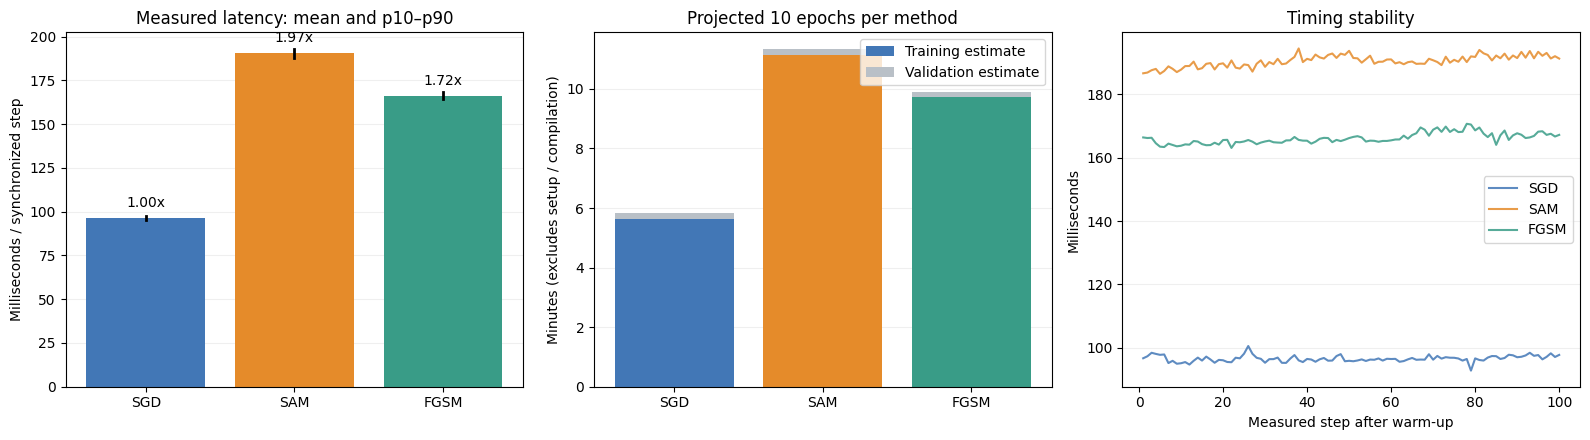

All three 10-epoch runs: estimated 27.1 minutes, plus compilation/setup and logging.
Use the stability plot to judge noise; p10–p90 describes steps, not uncertainty across independent runs.


In [10]:
require_phase('benchmark')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ORDER = ['SGD','SAM','FGSM']
COLORS = ['#4277b6','#e58b2a','#399c87']
raw = json.loads((RUN/'benchmark.json').read_text())
bench = pd.DataFrame([{k:v for k,v in r.items() if k != 'step_seconds'} for r in raw]).set_index('method').loc[ORDER]
bench['slowdown_vs_sgd'] = bench.mean_ms / bench.loc['SGD','mean_ms']
bench.to_csv(RUN/'benchmark_summary.csv')
display(bench.round(3))
fig, axes = plt.subplots(1,3,figsize=(16,4.5))
axes[0].bar(ORDER,bench.mean_ms,color=COLORS)
for i,m in enumerate(ORDER):
    axes[0].plot([i,i],[bench.loc[m,'p10_ms'],bench.loc[m,'p90_ms']],color='black',lw=2)
    axes[0].annotate(f"{bench.loc[m,'slowdown_vs_sgd']:.2f}x",(i,bench.loc[m,'mean_ms']),xytext=(0,8),textcoords='offset points',ha='center')
axes[0].set(title='Measured latency: mean and p10–p90',ylabel='Milliseconds / synchronized step')
axes[1].bar(ORDER,bench.estimated_train_minutes,color=COLORS,label='Training estimate')
axes[1].bar(ORDER,bench.estimated_total_minutes-bench.estimated_train_minutes,bottom=bench.estimated_train_minutes,color='#b9c0c7',label='Validation estimate')
axes[1].set(title='Projected 10 epochs per method',ylabel='Minutes (excludes setup / compilation)'); axes[1].legend()
for m,c in zip(ORDER,COLORS):
    r = next(r for r in raw if r['method']==m)
    axes[2].plot(np.arange(1,len(r['step_seconds'])+1),1000*np.array(r['step_seconds']),label=m,color=c,alpha=.85)
axes[2].set(title='Timing stability',xlabel='Measured step after warm-up',ylabel='Milliseconds'); axes[2].legend()
for ax in axes: ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RUN/'benchmark.png',dpi=180,bbox_inches='tight'); plt.show()
print(f"All three 10-epoch runs: estimated {bench.estimated_total_minutes.sum():.1f} minutes, plus compilation/setup and logging.")
print('Use the stability plot to judge noise; p10–p90 describes steps, not uncertainty across independent runs.')


## 7. Optional 10-epoch pilot
Set RUN_PILOT=True only after reviewing the estimate. Each method starts from the same initial weights and fresh momentum/BN state. The same ten-epoch cosine schedule applies to all. A one-hour cap stops partial runs explicitly. Final states are saved, but automatic resume is not implemented. Training may still cost roughly 35–40 minutes on the earlier T4; use the new measurements.


In [11]:
RUN_PILOT = True
if RUN_PILOT:
    require_phase('benchmark')
    rows=json.loads((RUN/'benchmark.json').read_text())
    projected=sum(r['estimated_total_minutes']*60+r['warmup_compile_seconds'] for r in rows)
    print('Estimated pilot including warm-up:',round(projected/60,1),'minutes')
    if projected>CFG['budget_seconds']:
        print('Skipped: exceeds the configured one-hour cap.')
    else:
        launch('pilot')
else:
    print('Pilot is off. No new accuracy results are implied by the benchmark.')


Estimated pilot including warm-up: 28.4 minutes
Launching pilot | revision clean-v4 | /content/runs/resnet18_clean_v3/20261113_230151_a29033
2026-11-13 23:09:33.050105: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:09:33.052876: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:09:34.588309: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:09:34.707896: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB deviceMemoryBand

## 8. Pilot accuracy and actual runtime


Pilot status: {'status': 'complete', 'wall_seconds': 1901.90879283, 'allocated_gpu_wall_hours': 0.528307998585}


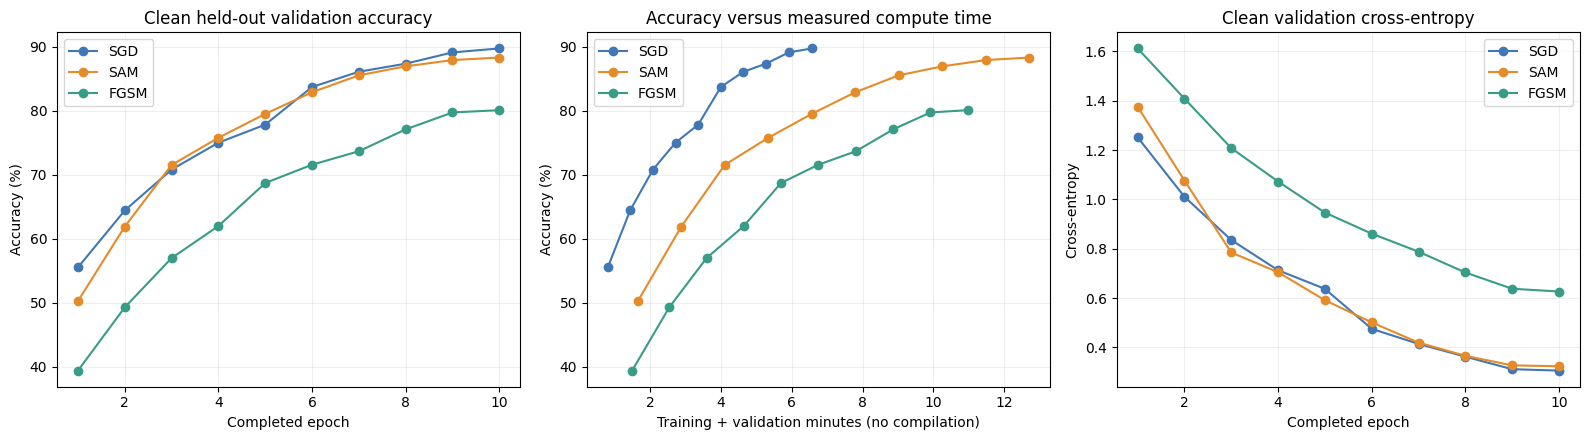

,epoch,train_seconds,eval_seconds,cumulative_train_seconds,cumulative_train_eval_seconds,last_lr,val_accuracy,val_loss,difference_vs_sgd_pp
method,,,,,,,,,
SGD,10,37.553,1.186,381.954,393.805,0.0,89.70,0.306,0.00
SAM,10,72.345,1.166,750.094,761.913,0.0,88.28,0.323,-1.42
FGSM,10,61.841,1.176,646.058,657.868,0.0,80.06,0.626,-9.64


Positive difference_vs_sgd_pp means higher final validation accuracy, in percentage points. One seed: no significance claim.


In [12]:
history_file = RUN/'pilot_history.json'
if history_file.exists():
    hist = pd.DataFrame(json.loads(history_file.read_text()))
    hist.to_csv(RUN/'pilot_history.csv',index=False)
    print('Pilot status:',json.loads((RUN/'pilot_status.json').read_text()))
    fig,axes = plt.subplots(1,3,figsize=(16,4.5))
    for m,c in zip(ORDER,COLORS):
        h = hist[hist.method==m]
        if h.empty: continue
        axes[0].plot(h.epoch,h.val_accuracy,'o-',label=m,color=c)
        axes[1].plot(h.cumulative_train_eval_seconds/60,h.val_accuracy,'o-',label=m,color=c)
        axes[2].plot(h.epoch,h.val_loss,'o-',label=m,color=c)
    axes[0].set(title='Clean held-out validation accuracy',xlabel='Completed epoch',ylabel='Accuracy (%)')
    axes[1].set(title='Accuracy versus measured compute time',xlabel='Training + validation minutes (no compilation)',ylabel='Accuracy (%)')
    axes[2].set(title='Clean validation cross-entropy',xlabel='Completed epoch',ylabel='Cross-entropy')
    for ax in axes: ax.grid(alpha=.2); ax.legend()
    fig.tight_layout(); fig.savefig(RUN/'pilot_curves.png',dpi=180,bbox_inches='tight'); plt.show()
    final = hist[hist.epoch==CFG['epochs']].set_index('method').copy()
    if not final.empty:
        if 'SGD' in final.index:
            final['difference_vs_sgd_pp'] = final.val_accuracy-final.loc['SGD','val_accuracy']
        final.to_csv(RUN/'final_epoch_summary.csv'); display(final.round(3))
    if len(final) != 3:
        print('Incomplete comparison: only methods with all 10 epochs appear in the final table.')
    print('Positive difference_vs_sgd_pp means higher final validation accuracy, in percentage points. One seed: no significance claim.')
else:
    print('No pilot accuracy data. Enable the optional pilot to populate these plots.')


## 9. Compare with the preserved original pilot
Keep negative results. This is a single-seed comparison; it does not establish statistical significance or isolate flatness as a cause. If other hyperparameters or seeds were changed, this is no longer a one-factor Nesterov comparison.


In [13]:
if (RUN/'pilot_history.json').exists():
    new = pd.DataFrame(json.loads((RUN/'pilot_history.json').read_text()))
    last = new[new.epoch==CFG['epochs']].set_index('method')
    original = pd.Series({'SGD':89.36,'SAM':88.02,'FGSM':79.52},name='original_momentum_accuracy')
    comparison = pd.concat([original,last.val_accuracy.rename('new_accuracy')],axis=1)
    comparison['change_pp']=comparison.new_accuracy-comparison.original_momentum_accuracy
    display(comparison.round(3))
    comparison.to_csv(RUN/'comparison_with_original_pilot.csv')
    print('Original seed=42, split_seed=42, epochs=10, Nesterov=False. New config:',CFG)
else:
    print('No new pilot results. The archived run is unchanged.')


,original_momentum_accuracy,new_accuracy,change_pp
SGD,89.36,89.70,0.34
SAM,88.02,88.28,0.26
FGSM,79.52,80.06,0.54


Original seed=42, split_seed=42, epochs=10, Nesterov=False. New config: {'seed': 42, 'split_seed': 42, 'nesterov': True, 'batch_size': 128, 'warmup': 20, 'timed_steps': 100, 'epochs': 10, 'lr': 0.1, 'momentum': 0.9, 'weight_decay': 0.0005, 'clip': 5.0, 'rho': 0.05, 'epsilon': 0.01568627450980392, 'budget_seconds': 3600, 'data_dir': '/root/tensorflow_datasets', 'repo': '/content/work/sam', 'output': '/content/runs/resnet18_clean_v3/20261113_230151_a29033'}


## 10. Download the CURRENT run's debugging files
Run this even after an error. It packages the exact worker, config, diagnostic report, environment and log files from RUN. The archive excludes datasets and model checkpoints. For full preservation, also save the entire run folder (including final .msgpack files) to Drive. Downloading this bundle uses no GPU compute.


In [14]:
bundle=export_debug()
print('Downloading current run:',RUN)
from google.colab import files
files.download(str(bundle))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>